In [3]:
import pandas as pd                                                                      
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sea
from sklearn.preprocessing import StandardScaler

In [12]:
data= pd.read_csv("world_feature_engineering_dataset.csv")

In [13]:
df = data.copy()

In [14]:
print("Size of df:", df.shape)

Size of df: (20, 13)


In [15]:
print("Informaion about data")
display(df.info())

Informaion about data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   20 non-null     object 
 1   population_millions       20 non-null     int64  
 2   gdp_billion_usd           20 non-null     int64  
 3   area_km2                  20 non-null     int64  
 4   internet_penetration_pct  20 non-null     int64  
 5   literacy_rate_pct         20 non-null     int64  
 6   urban_population_pct      20 non-null     int64  
 7   median_age                20 non-null     int64  
 8   co2_emission_per_capita   20 non-null     float64
 9   gdp_per_capita            20 non-null     float64
 10  population_density        20 non-null     float64
 11  digital_index             20 non-null     float64
 12  development_score         20 non-null     float64
dtypes: float64(5), int64(7), object(1)
memory usa

None

No null values found, Country is an object, all others are numeric columns.

Let us look at the dataset

In [17]:
display(df.head())

display(df.sample(5))

,country,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
0,USA,1131,5101,2458388,83,55,26,30,9.95,4510.167993,460.057566,71.8,26.965508
1,China,865,6470,8946786,33,79,92,30,4.05,7479.768786,96.682764,51.4,34.193988
2,India,1299,17618,2693046,83,61,91,41,17.00,13562.740570,482.353439,74.2,41.138137
3,Germany,1135,20989,5529720,92,63,31,25,10.98,18492.511013,205.254516,80.4,31.244626
4,UK,1100,19819,6670913,47,78,53,43,12.66,18017.272727,164.894970,59.4,29.320864


,country,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
12,Indonesia,876,19168,4086518,69,89,84,44,15.96,21881.278539,214.363426,77.0,40.994064
11,Turkey,1128,239,2775683,91,62,54,35,7.79,211.879433,406.386464,79.4,34.630594
6,Brazil,126,8716,3415659,63,98,67,34,11.43,69174.603175,36.888928,77.0,39.958730
4,UK,1100,19819,6670913,47,78,53,43,12.66,18017.272727,164.894970,59.4,29.320864
18,South Africa,390,17962,6279859,58,95,46,22,11.83,46056.410256,62.103305,72.8,33.342821


In [18]:
display(df['country'])

0              USA
1            China
2            India
3          Germany
4               UK
5           France
6           Brazil
7           Canada
8        Australia
9            Japan
10        Pakistan
11          Turkey
12       Indonesia
13         Nigeria
14          Mexico
15           Italy
16           Spain
17          Russia
18    South Africa
19    Saudi Arabia
Name: country, dtype: object

In [24]:
print("Data Quality Checks: \n")

print("Numer of nullvalues: ")
display(df.isna().sum())

print("\nAlthough there are no null or duplicated values we are still checking it \n")

print("Number of duplicate rows: ", df.duplicated().sum())

Data Quality Checks: 

Numer of nullvalues: 


country                     0
population_millions         0
gdp_billion_usd             0
area_km2                    0
internet_penetration_pct    0
literacy_rate_pct           0
urban_population_pct        0
median_age                  0
co2_emission_per_capita     0
gdp_per_capita              0
population_density          0
digital_index               0
development_score           0
dtype: int64


Although there are no null or duplicated values we are still checking it 

Number of duplicate rows:  0


In [26]:
print("Statistic Summary: ")
display(df.describe())

Statistic Summary: 


,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
count,20.000000,20.000000,2.000000e+01,20.000000,20.000000,20.000000,20.000000,20.00000,20.000000,20.000000,20.00000,20.000000
mean,793.200000,12505.300000,3.787281e+06,67.000000,75.850000,51.550000,33.800000,8.80450,23616.862639,410.020600,70.54000,32.652843
std,428.944678,8479.400327,2.136956e+06,18.881904,14.776493,23.444167,9.589468,5.07259,21583.261888,734.965790,11.17631,5.633920
min,92.000000,239.000000,9.814800e+04,33.000000,55.000000,20.000000,19.000000,0.51000,211.879433,36.888928,51.40000,21.105904
25%,379.500000,4589.500000,2.427644e+06,51.500000,62.000000,30.250000,27.250000,5.02500,7146.051566,114.478915,59.35000,30.161188
50%,870.500000,14531.000000,3.415508e+06,69.500000,78.000000,52.500000,33.000000,8.14000,18254.891870,199.394538,72.50000,33.768404
75%,1132.000000,19330.750000,5.153351e+06,83.000000,89.000000,66.250000,43.250000,12.03750,32882.309840,419.804240,79.25000,35.666872
max,1337.000000,24283.000000,8.946786e+06,92.000000,98.000000,92.000000,47.000000,17.00000,69448.275862,3413.212699,91.80000,41.138137


## UNI-VARIATE-ANALYSIS

Let us identify ourliers, distribution of each column, skweness

In [32]:
numerical_columns = df.iloc[:, 1:]

In [38]:
num_cols = [f for f in df.columns if df[f].dtype != 'object']
num_cols

['population_millions',
 'gdp_billion_usd',
 'area_km2',
 'internet_penetration_pct',
 'literacy_rate_pct',
 'urban_population_pct',
 'median_age',
 'co2_emission_per_capita',
 'gdp_per_capita',
 'population_density',
 'digital_index',
 'development_score']

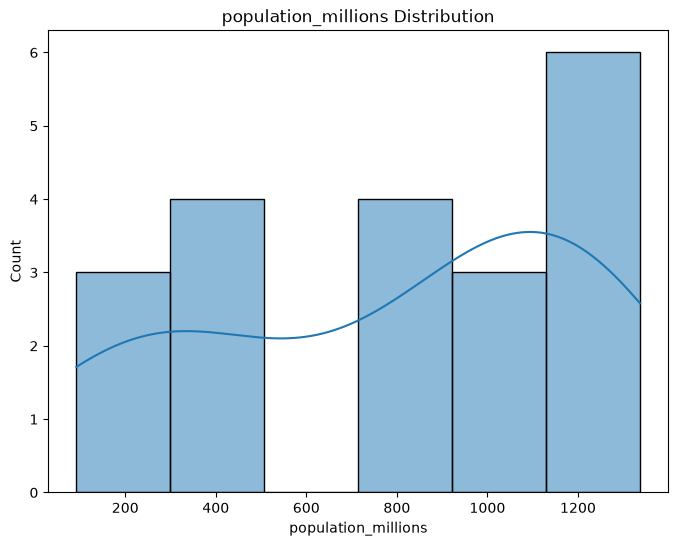

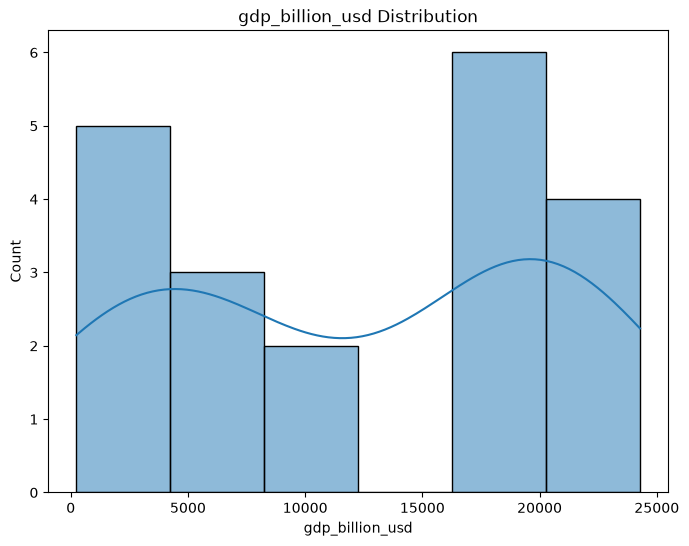

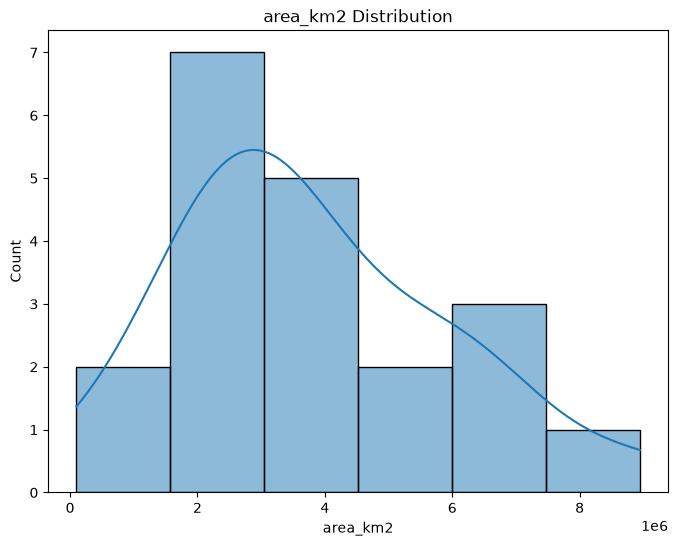

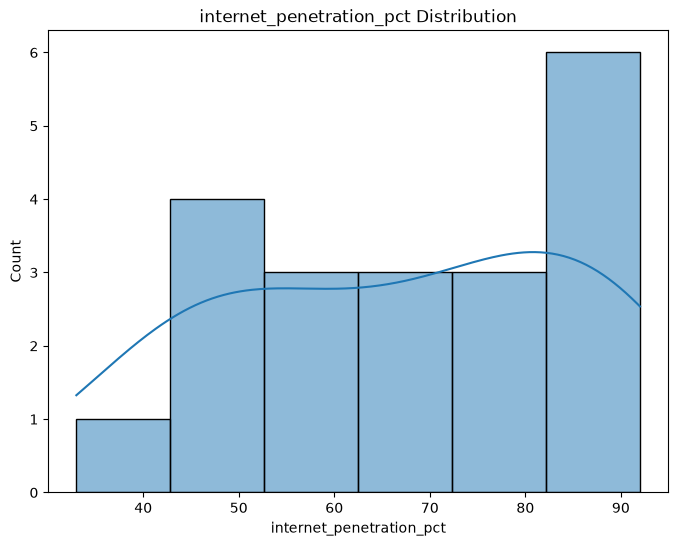

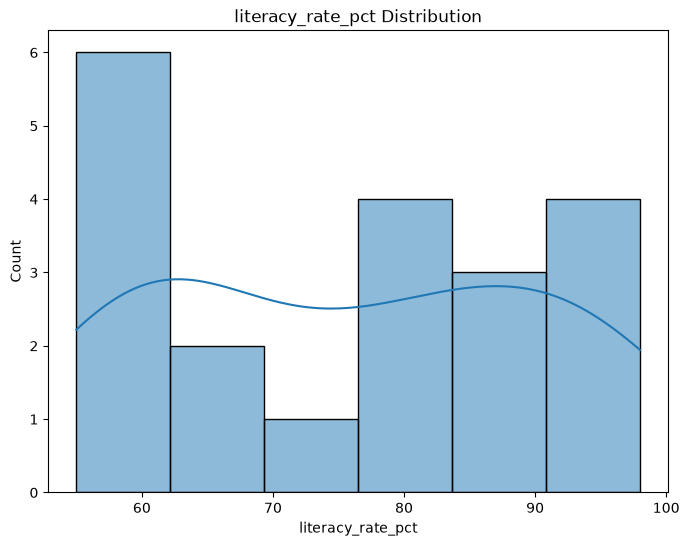

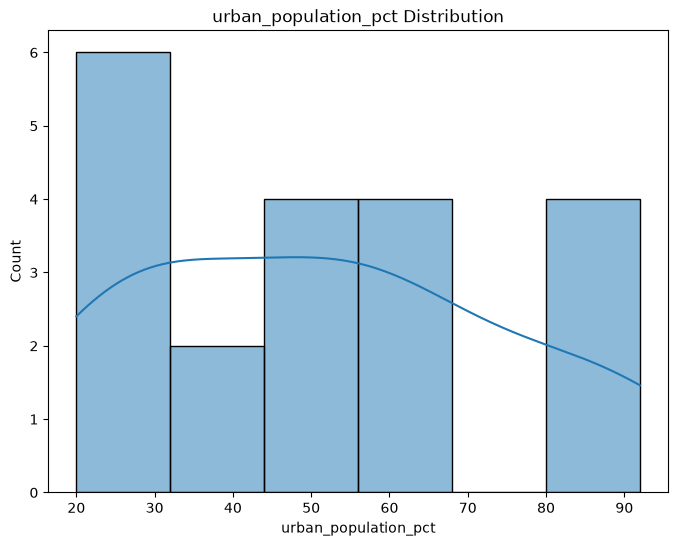

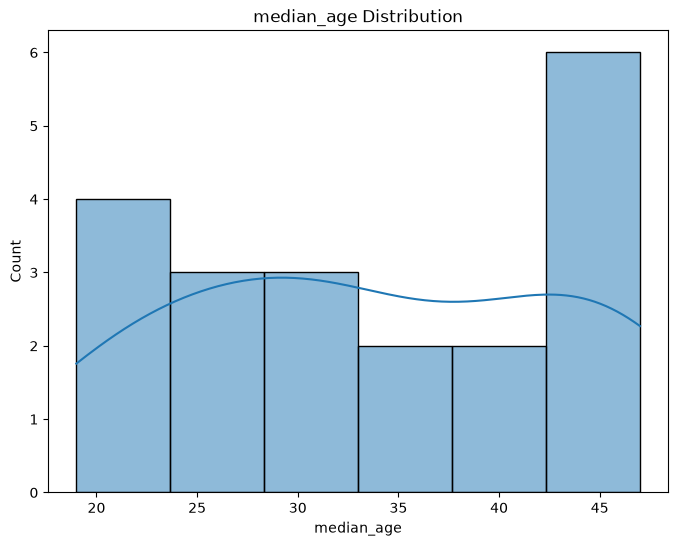

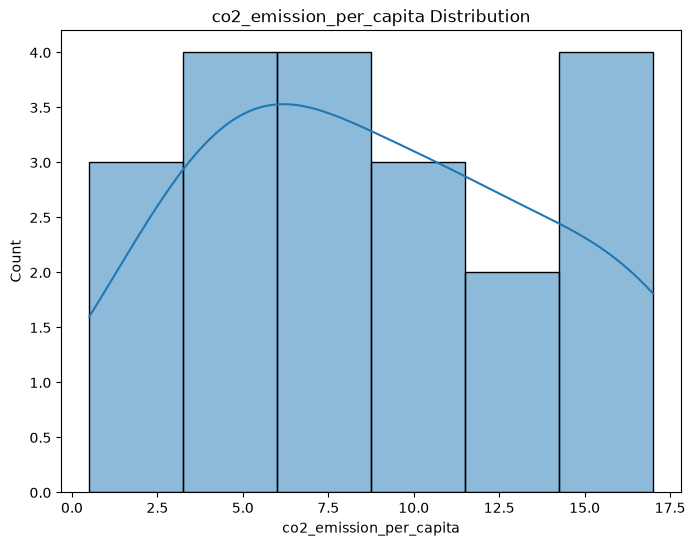

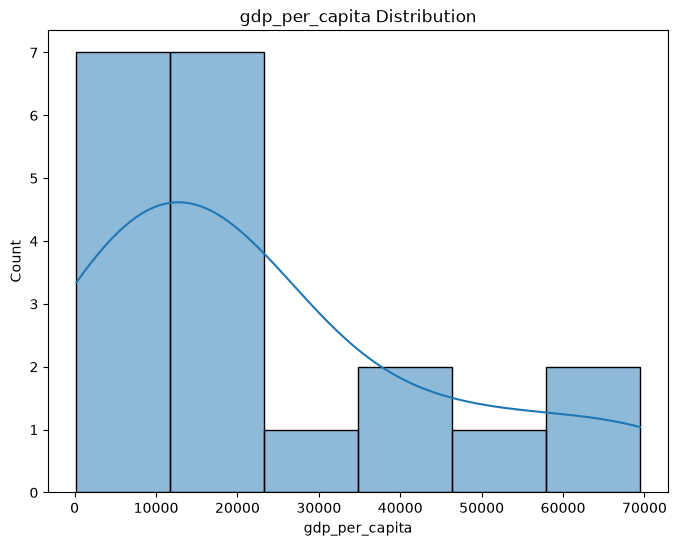

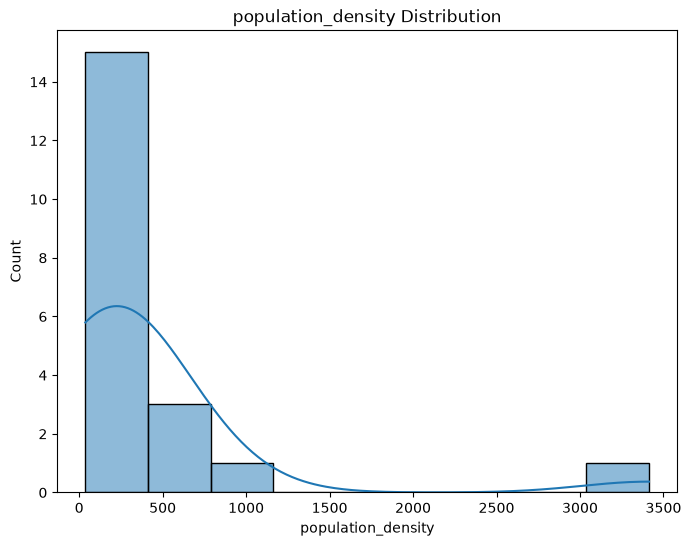

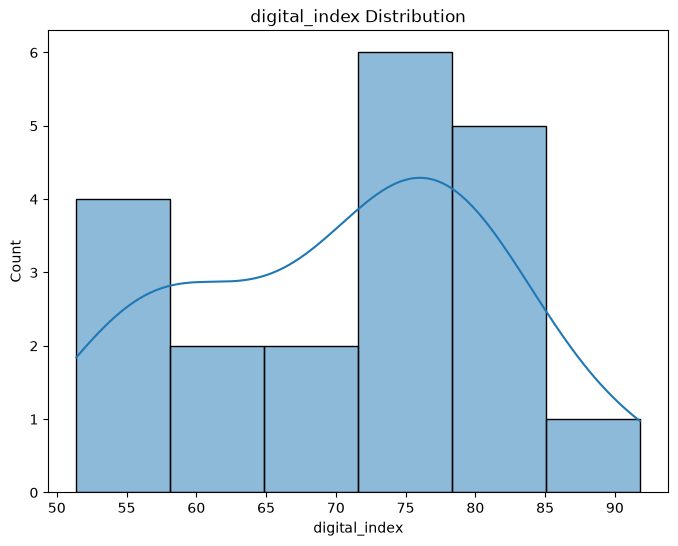

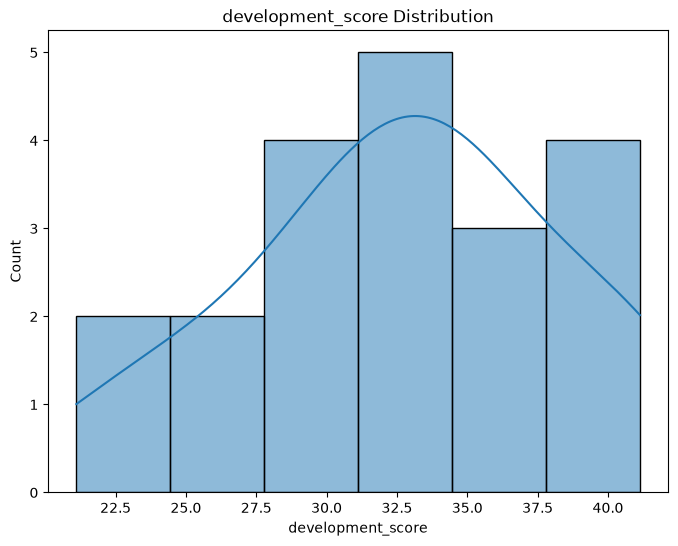

In [41]:
for cols in num_cols:
    plt.figure(figsize=(8,6))
    sea.histplot(data=df, x=cols, kde=True)
    plt.title(f"{cols} Distribution")
    plt.show()

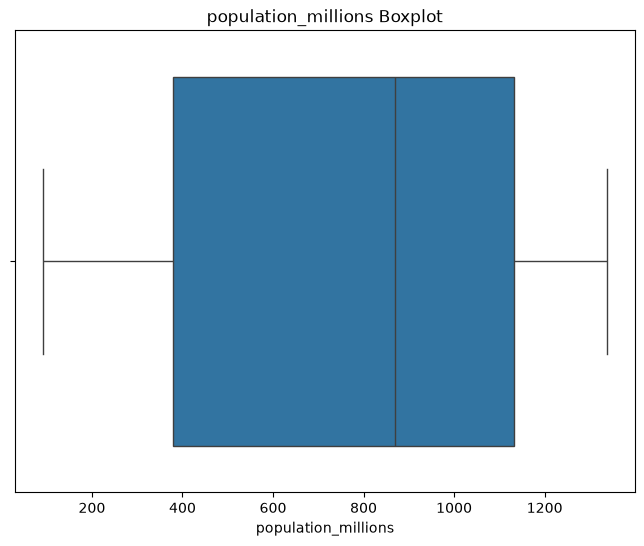

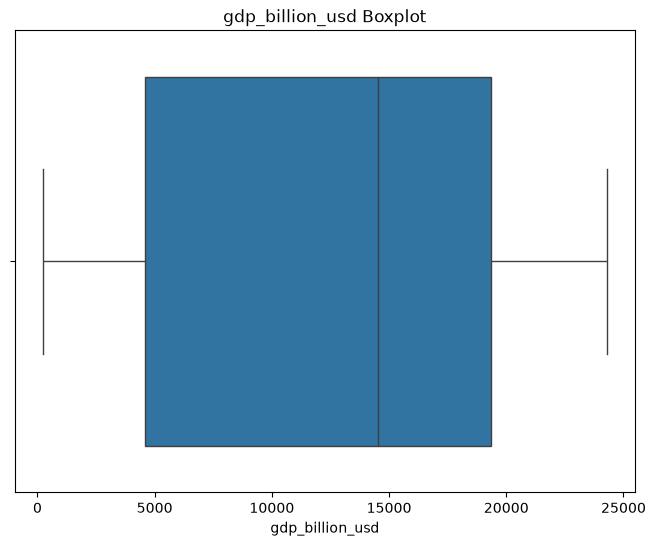

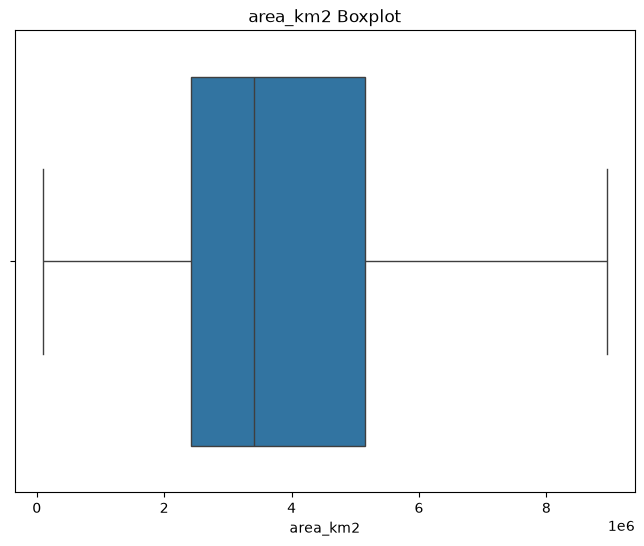

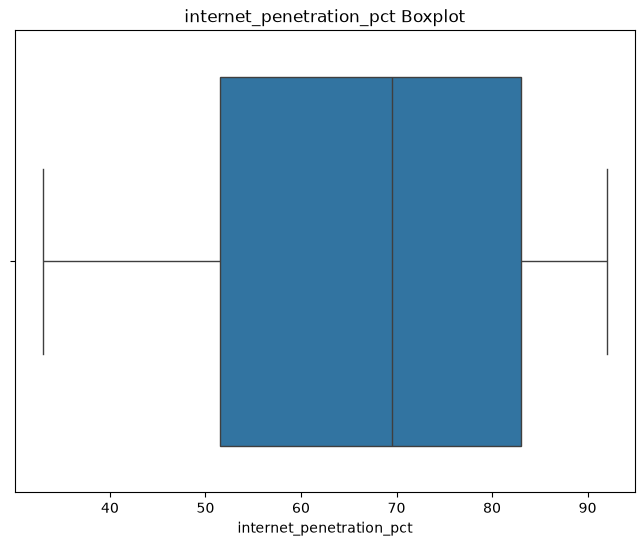

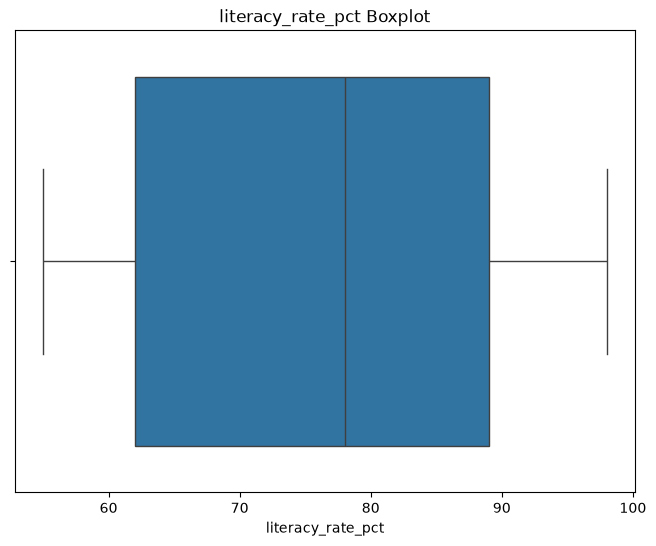

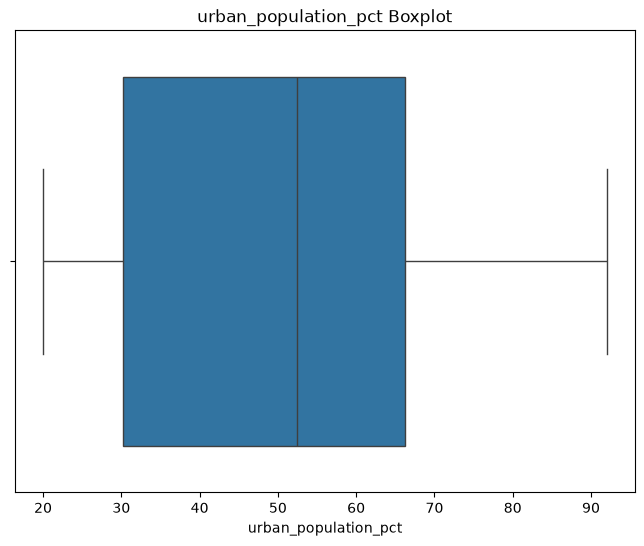

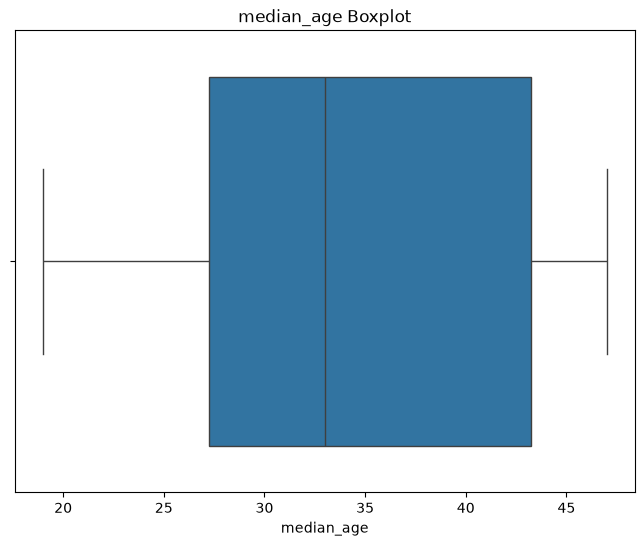

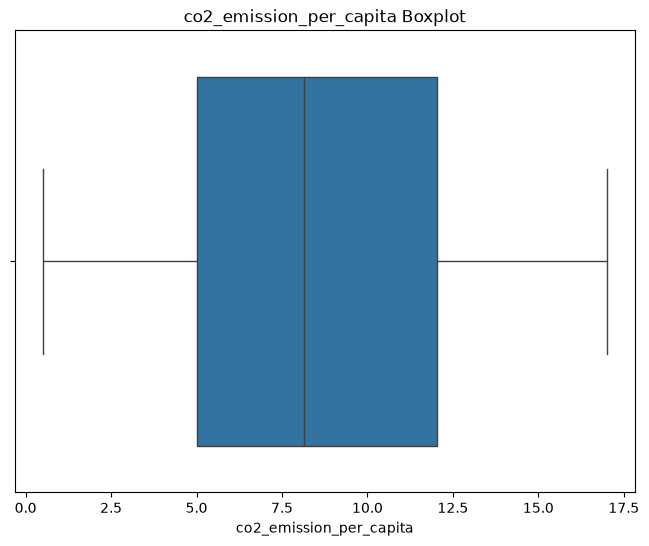

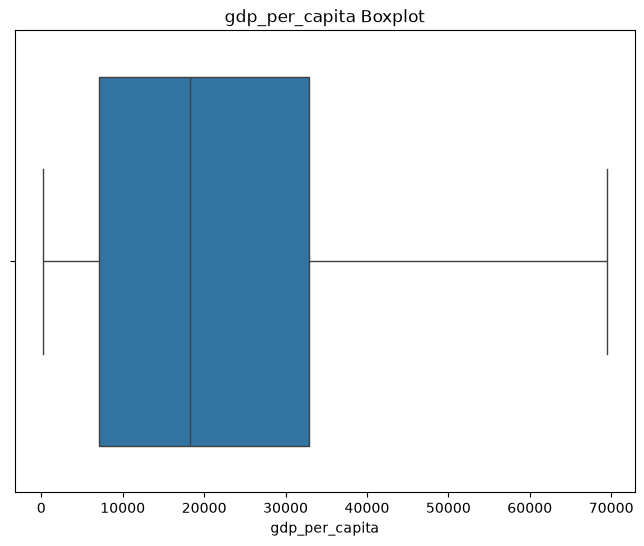

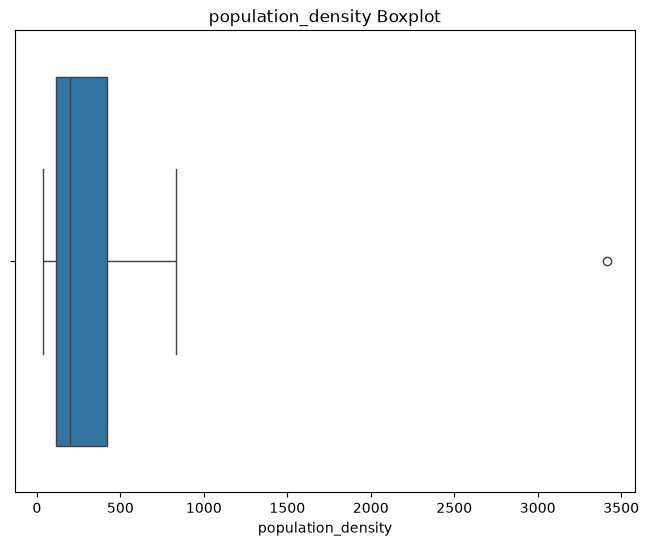

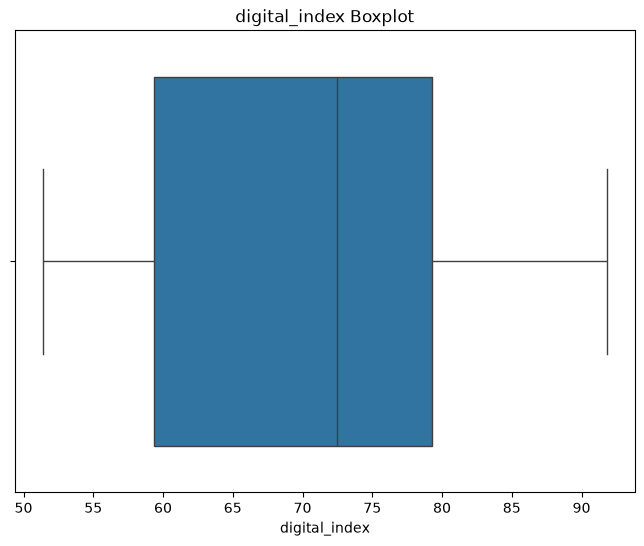

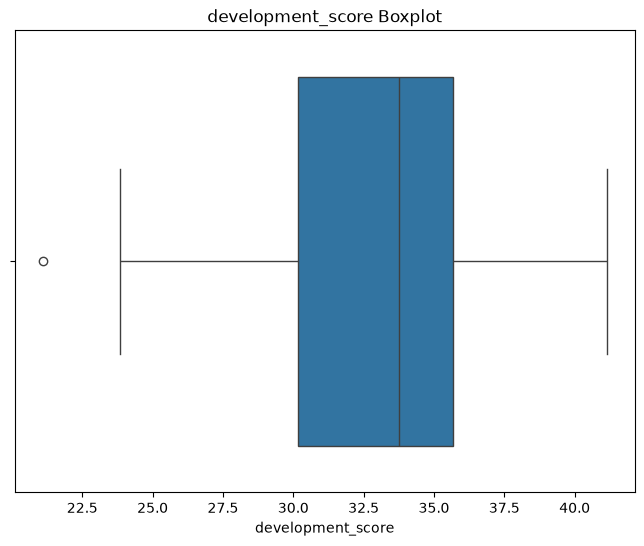

In [42]:
for cols in num_cols:
    plt.figure(figsize=(8,6))
    sea.boxplot(data=df, x=cols)
    plt.title(f"{cols} Boxplot")
    plt.show()

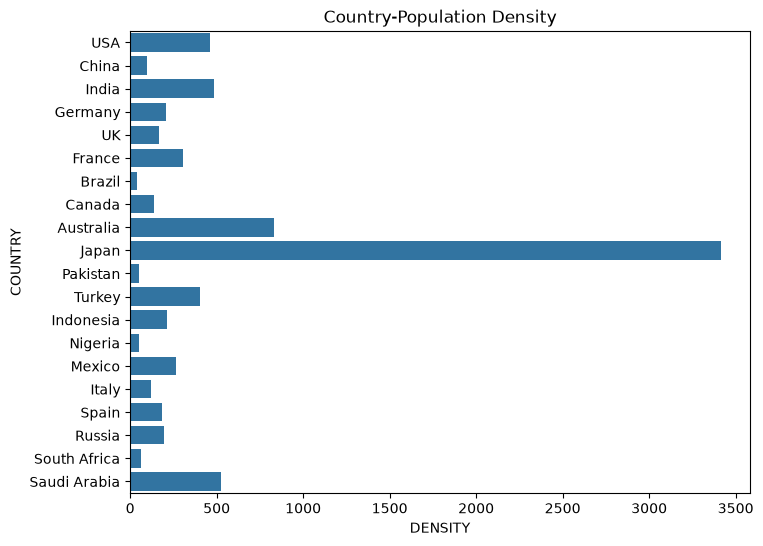

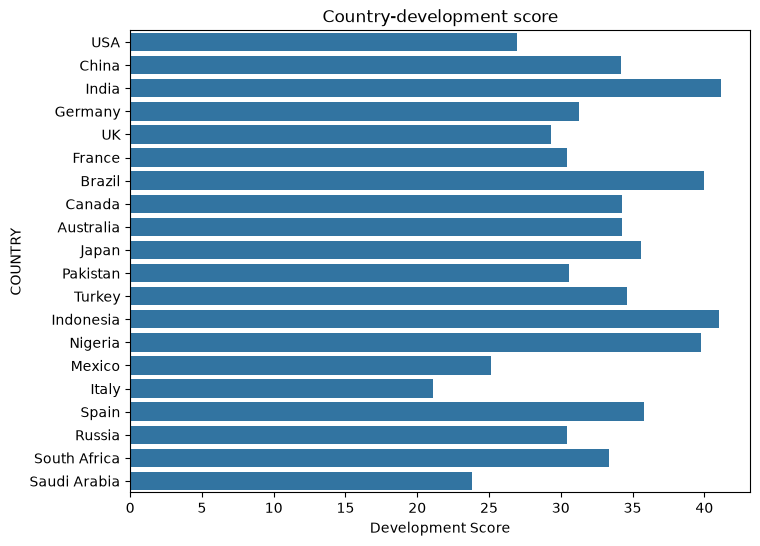

In [48]:
## Bivariate

plt.figure(figsize=(8,6))
sea.barplot(data=df, x='population_density', y='country', legend=False)
plt.title("Country-Population Density")
plt.xlabel("DENSITY")
plt.ylabel("COUNTRY")
plt.show()

plt.figure(figsize=(8,6))
sea.barplot(data=df, x='development_score', y='country', legend=False)
plt.title("Country-development score")
plt.xlabel("Development Score")
plt.ylabel("COUNTRY")
plt.show()


In [49]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')

In [57]:
df[['internet_penetration_pct', 'digital_index']].corr()

,internet_penetration_pct,digital_index
internet_penetration_pct,1.000000,0.862137
digital_index,0.862137,1.000000


I think that my target variable is development score. But as the dataset is tooo less we are only gonna be using it for EDA and Feature Engineering.

# Project 1: EDA
We answer some questions by plotting graphs and by using multiple parameters to answer them.

Top 10 Largest Countries


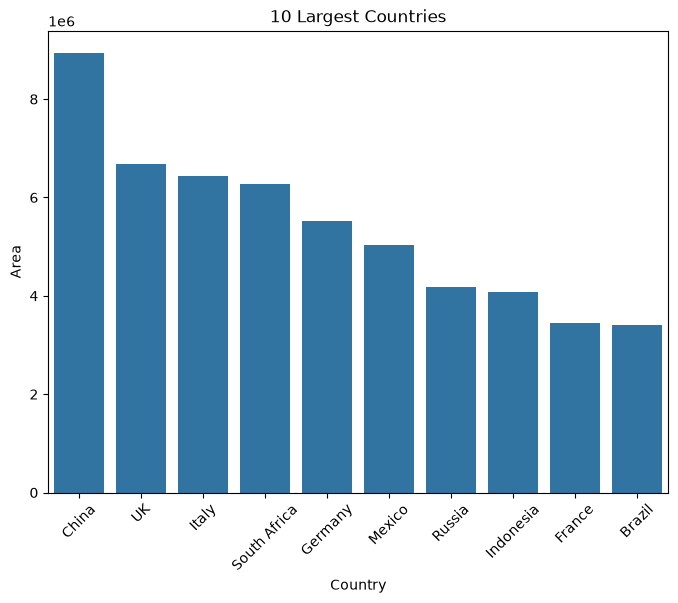

In [77]:
print("Top 10 Largest Countries")
largest_10_countries = df.sort_values(by='area_km2',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=largest_10_countries.head(10), x='country', y='area_km2', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Area")
plt.show()


Top GDP Countries


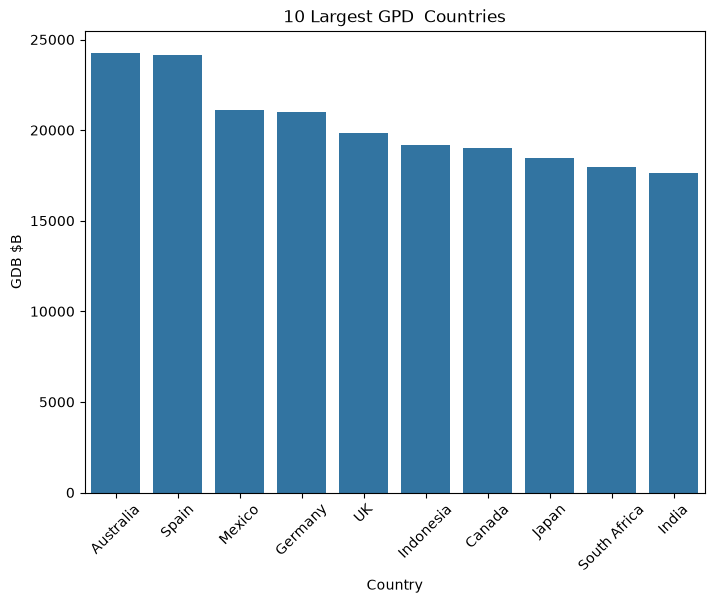

In [78]:
print("Top GDP Countries")
top_gdp_countries = df.sort_values(by='gdp_billion_usd', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=top_gdp_countries.head(10), x='country', y='gdp_billion_usd', legend=False)
plt.title("10 Largest GPD  Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("GDB $B")
plt.show()

High Literacy rate Countries


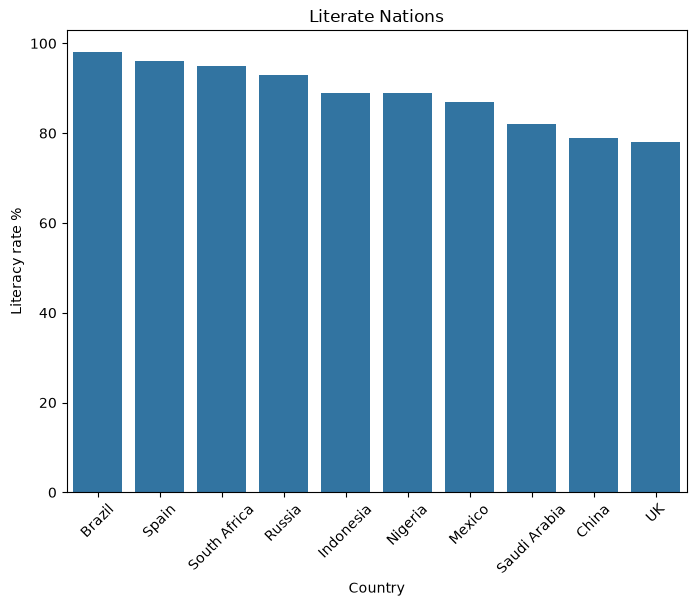

In [79]:
print("High Literacy rate Countries")
highly_literate_countries = df.sort_values(by='literacy_rate_pct',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=highly_literate_countries.head(10), x='country', y="literacy_rate_pct", legend=False)
plt.title("Literate Nations")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Literacy rate %")
plt.show()

In [53]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')

Country Population Average Age, from highest to lowest (old to youth population


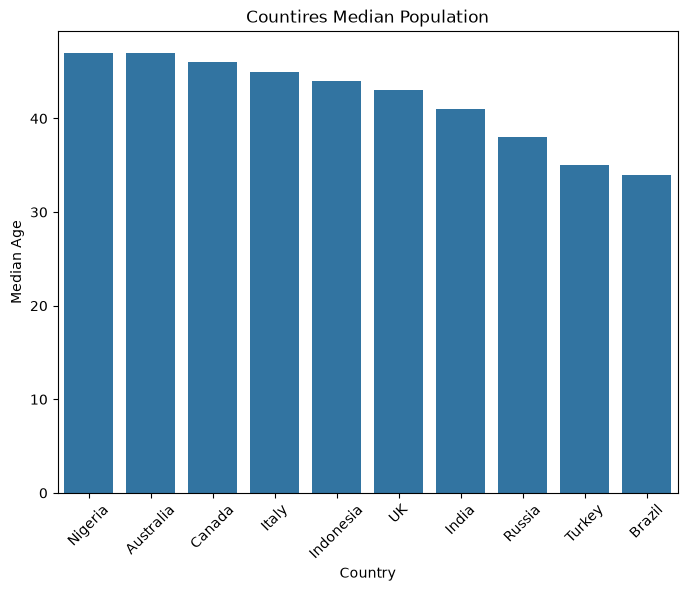

In [82]:
print("Country Population Average Age, from highest to lowest (old to youth population")
median_sorted = df.sort_values(by='median_age', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=median_sorted.head(10), x='country', y='median_age', legend=False)
plt.title("Countires Median Population")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Median Age")
plt.show()

Dominant CO2 Emitting contries


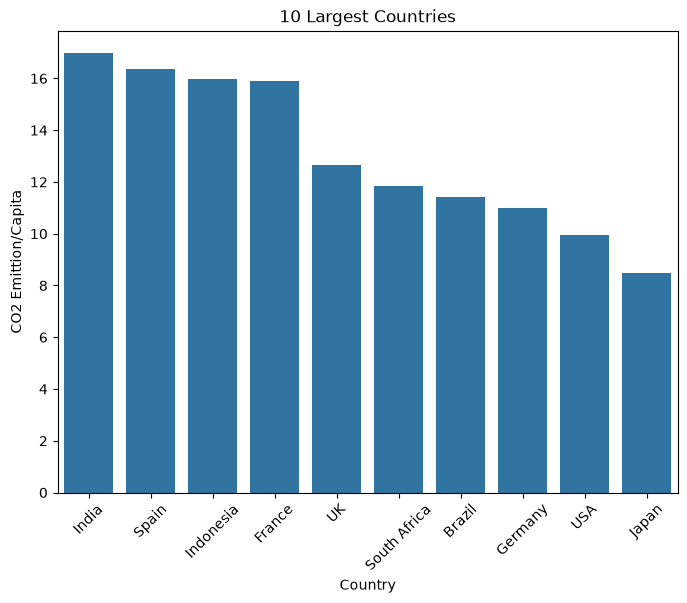

In [84]:
print("Dominant CO2 Emitting contries")
top_10_co2_emitters = df.sort_values(by='co2_emission_per_capita', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=top_10_co2_emitters.head(10), x='country', y='co2_emission_per_capita', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("CO2 Emittion/Capita")
plt.show()

Least Internet Connected Country Population


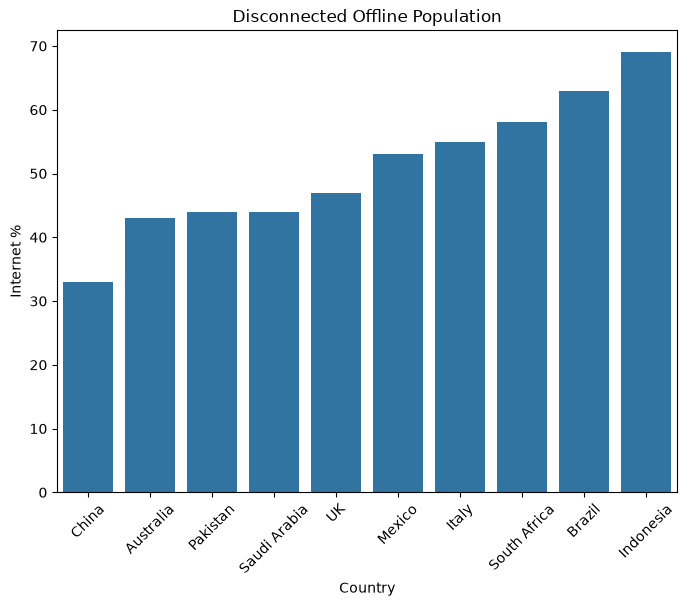

In [85]:
print("Least Internet Connected Country Population")
least_internet_connected = df.sort_values(by='internet_penetration_pct')
plt.figure(figsize=(8,6))
sea.barplot(data=least_internet_connected.head(10), x='country', y='internet_penetration_pct', legend=False)
plt.title("Disconnected Offline Population")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Internet %")
plt.show()

Influence of internet on Digital Index: 


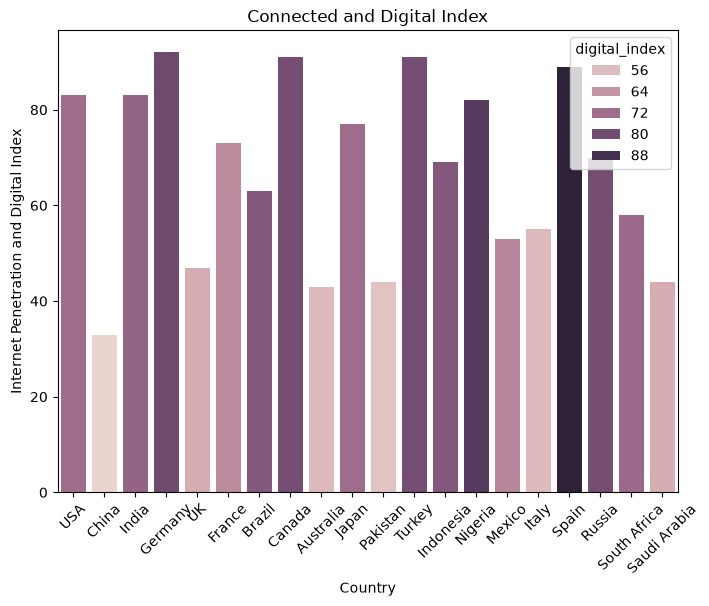

In [93]:
print("Influence of internet on Digital Index: ")
plt.figure(figsize=(8,6))
sea.barplot(data=df, x='country', y='internet_penetration_pct',hue='digital_index')
plt.title("Connected and Digital Index")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Internet Penetration and Digital Index")
plt.show()

GDP BIllion and GDP per Capita


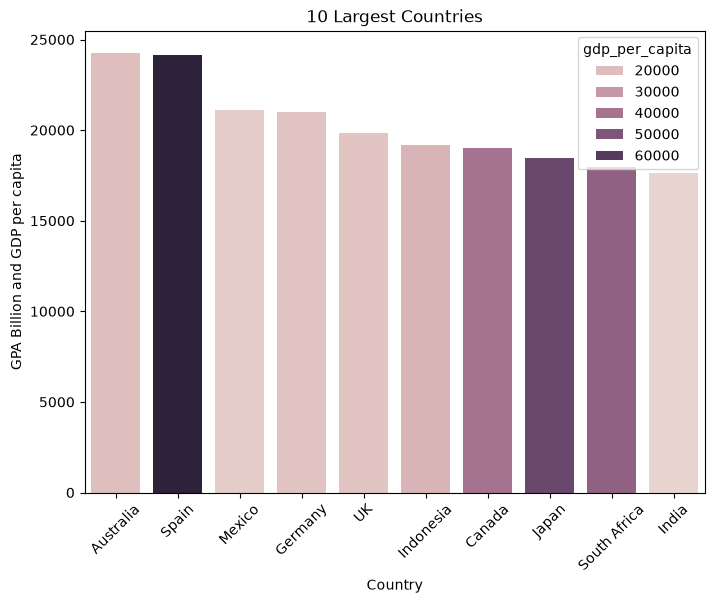

In [95]:
print("GDP BIllion and GDP per Capita")
top_gdp_countries
plt.figure(figsize=(8,6))
sea.barplot(data=top_gdp_countries.head(10), x='country', y='gdp_billion_usd',hue='gdp_per_capita')
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("GPA Billion and GDP per capita")
plt.show()

Urban Population and CO2 Emission


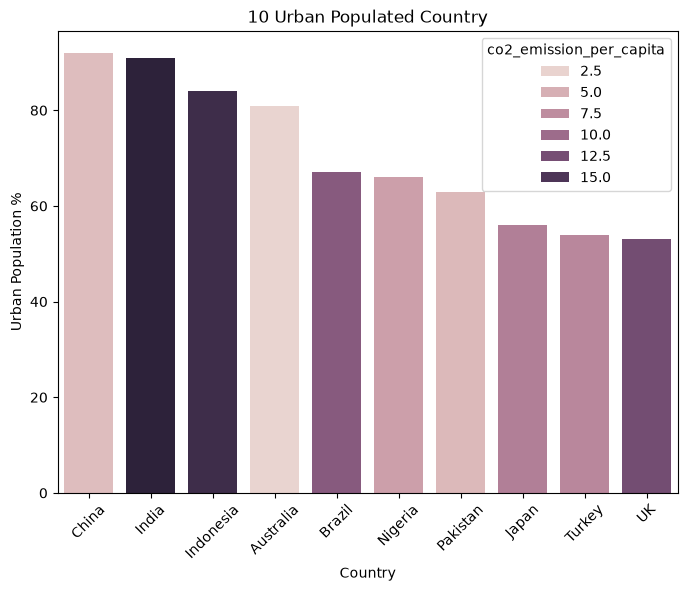

In [98]:
print("Urban Population and CO2 Emission")
df[['urban_population_pct','co2_emission_per_capita']].corr()
most_urban_populated_contries = df.sort_values(by='urban_population_pct',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=most_urban_populated_contries.head(10), x='country', y='urban_population_pct', hue='co2_emission_per_capita')
plt.title("10 Urban Populated Country")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Urban Population %")
plt.show()

population and area correlation


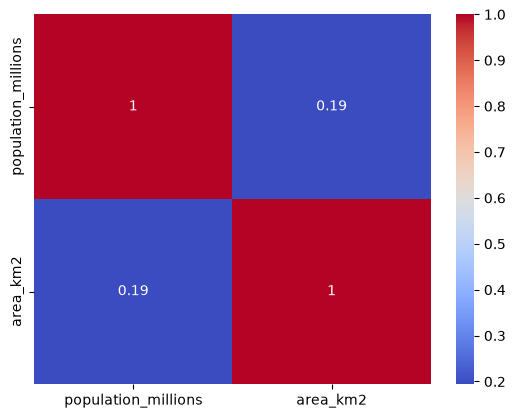

In [100]:
print("population and area correlation")
corr_pop_area = df[['population_millions','area_km2']].corr()
sea.heatmap(corr_pop_area,cmap='coolwarm',annot=True)
plt.show()

In [102]:
print("Population and Development score")
pop_development_corr = df[['population_millions', 'development_score']].corr()
display(pop_development_corr)

Population and Development score


,population_millions,development_score
population_millions,1.000000,-0.365902
development_score,-0.365902,1.000000


Internet + Digital Index == Development score


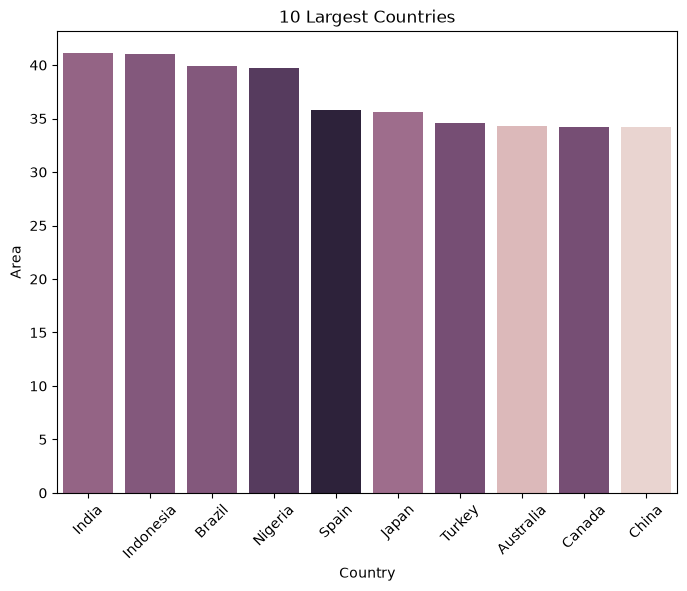

In [111]:
print("Internet + Digital Index == Development score")
techno_advanced_contry = df.sort_values(by='development_score', ascending=False)
techno_advanced_contry
plt.figure(figsize=(8,6))
sea.barplot(data=techno_advanced_contry.head(10), x='country', y='development_score',hue='digital_index', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Area")
plt.show()


I am thinking it is a toy dataset cause australia was never among top GDP's and thisis

In [96]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')